# Praktikum 3 - Regresi dengan Keras

Praktikum ini memakai JST untuk regresi. Ada dua bagian:

1. **Data dummy** luas/harga untuk melihat pengaruh learning rate.
2. **California Housing** untuk regresi harga rumah yang lebih realistis, sekaligus membandingkan beberapa learning rate.

Dataset Boston tidak dipakai karena `load_boston` sudah dihapus dari scikit-learn. Sebagai gantinya digunakan `fetch_california_housing` yang tersedia langsung di scikit-learn.

## 1. Import Library

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## Bagian A - Data Dummy Luas dan Harga

### A.1 Dataset dan Split

Data dibagi lebih dahulu, lalu scaler di-`fit` hanya pada data latih agar tidak terjadi data leakage.

In [2]:
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900],
})

X_dummy = data[['luas']].values
y_dummy = data[['harga']].values

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_dummy, y_dummy, test_size=0.2, random_state=SEED
)

x_scaler_d = StandardScaler()
y_scaler_d = StandardScaler()

X_train_d = x_scaler_d.fit_transform(X_train_d)
X_test_d = x_scaler_d.transform(X_test_d)

y_train_d = y_scaler_d.fit_transform(y_train_d)
y_test_d = y_scaler_d.transform(y_test_d)

print('Data latih:', X_train_d.shape)
print('Data uji  :', X_test_d.shape)

Data latih: (4, 1)
Data uji  : (1, 1)


### A.2 Model dan Eksperimen Learning Rate

In [3]:
def build_dummy_model(learning_rate):
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
    )

    return model

In [4]:
learning_rates_dummy = [0.1, 0.01, 0.001]
dummy_results = []

for lr in learning_rates_dummy:
    tf.keras.utils.set_random_seed(SEED)

    model = build_dummy_model(lr)

    start = time.perf_counter()
    history = model.fit(
        X_train_d, y_train_d,
        epochs=100,
        verbose=0,
    )
    training_time = time.perf_counter() - start

    test_loss = model.evaluate(X_test_d, y_test_d, verbose=0)

    pred_scaled = model.predict(X_test_d, verbose=0)
    pred_asli = y_scaler_d.inverse_transform(pred_scaled)

    dummy_results.append({
        'learning_rate': lr,
        'history': history.history['loss'],
        'final_train_loss': history.history['loss'][-1],
        'test_loss': test_loss,
        'prediksi': pred_asli.ravel(),
        'waktu': training_time,
    })

    print(f"LR={lr}: final train loss={history.history['loss'][-1]:.6f}, "
          f"test loss={test_loss:.6f}, waktu={training_time:.2f} s")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR=0.1: final train loss=0.000006, test loss=0.009332, waktu=5.26 s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR=0.01: final train loss=0.002722, test loss=0.011052, waktu=6.48 s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR=0.001: final train loss=0.710428, test loss=0.741159, waktu=5.07 s


### A.3 Tabel dan Grafik Data Dummy

In [5]:
tabel_dummy = pd.DataFrame([
    {
        'Learning Rate': r['learning_rate'],
        'Final Train Loss': round(r['final_train_loss'], 6),
        'Test Loss': round(r['test_loss'], 6),
        'Waktu (s)': round(r['waktu'], 2),
        'Prediksi Harga': np.round(r['prediksi'], 2).tolist(),
    }
    for r in dummy_results
])

tabel_dummy

,Learning Rate,Final Train Loss,Test Loss,Waktu (s),Prediksi Harga
0,0.100,0.000006,0.009332,5.26,[585.7100219726562]
1,0.010,0.002722,0.011052,6.48,[584.4500122070312]
2,0.001,0.710428,0.741159,5.07,[727.3300170898438]


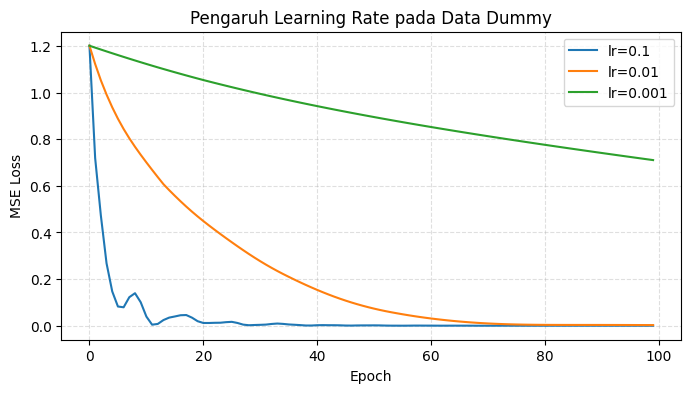

In [6]:
plt.figure(figsize=(8, 4))

for r in dummy_results:
    plt.plot(r['history'], label=f"lr={r['learning_rate']}")

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Pengaruh Learning Rate pada Data Dummy')
plt.legend()
plt.grid(True, ls='--', alpha=0.4)
plt.show()

## Bagian B - California Housing

### B.1 Load Dataset dan Split

Dataset diunduh otomatis oleh scikit-learn. Target adalah median house value dalam satuan 100.000 USD. Data dibagi 80% latih dan 20% validasi.

In [7]:
housing = fetch_california_housing()

X_house = housing.data
y_house = housing.target

X_train_h, X_val_h, y_train_h, y_val_h = train_test_split(
    X_house, y_house, test_size=0.2, random_state=SEED
)

x_scaler_h = StandardScaler()
X_train_h = x_scaler_h.fit_transform(X_train_h)
X_val_h = x_scaler_h.transform(X_val_h)

print('Fitur:', housing.feature_names)
print('Data latih:', X_train_h.shape)
print('Data validasi:', X_val_h.shape)
print('Rentang target:', y_house.min(), '-', y_house.max())

Fitur: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Data latih: (16512, 8)
Data validasi: (4128, 8)
Rentang target: 0.14999 - 5.00001


### B.2 Model dan Eksperimen Learning Rate

In [8]:
def build_house_model(learning_rate):
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train_h.shape[1],)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae'],
    )

    return model

In [9]:
learning_rates_house = [0.01, 0.001, 0.0001]
house_results = []

for lr in learning_rates_house:
    tf.keras.utils.set_random_seed(SEED)

    model = build_house_model(lr)

    start = time.perf_counter()
    history = model.fit(
        X_train_h, y_train_h,
        validation_data=(X_val_h, y_val_h),
        epochs=50,
        batch_size=32,
        verbose=0,
    )
    training_time = time.perf_counter() - start

    pred = model.predict(X_val_h, verbose=0).ravel()
    rmse = np.sqrt(mean_squared_error(y_val_h, pred))
    mae = mean_absolute_error(y_val_h, pred)

    house_results.append({
        'learning_rate': lr,
        'history': history.history,
        'val_loss': history.history['val_loss'][-1],
        'val_mae': history.history['val_mae'][-1],
        'rmse': rmse,
        'mae': mae,
        'waktu': training_time,
    })

    print(f"LR={lr}: val loss={history.history['val_loss'][-1]:.4f}, "
          f"val MAE={history.history['val_mae'][-1]:.4f}, "
          f"RMSE={rmse:.4f}, waktu={training_time:.2f} s")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR=0.01: val loss=0.2793, val MAE=0.3606, RMSE=0.5285, waktu=76.22 s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR=0.001: val loss=0.2820, val MAE=0.3655, RMSE=0.5310, waktu=79.20 s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


LR=0.0001: val loss=0.3335, val MAE=0.4022, RMSE=0.5775, waktu=80.09 s


### B.3 Tabel dan Grafik California Housing

In [10]:
tabel_house = pd.DataFrame([
    {
        'Learning Rate': r['learning_rate'],
        'Val Loss (MSE)': round(r['val_loss'], 4),
        'Val MAE': round(r['val_mae'], 4),
        'RMSE': round(r['rmse'], 4),
        'Waktu (s)': round(r['waktu'], 2),
    }
    for r in house_results
])

tabel_house

,Learning Rate,Val Loss (MSE),Val MAE,RMSE,Waktu (s)
0,0.0100,0.2793,0.3606,0.5285,76.22
1,0.0010,0.2820,0.3655,0.5310,79.20
2,0.0001,0.3335,0.4022,0.5775,80.09


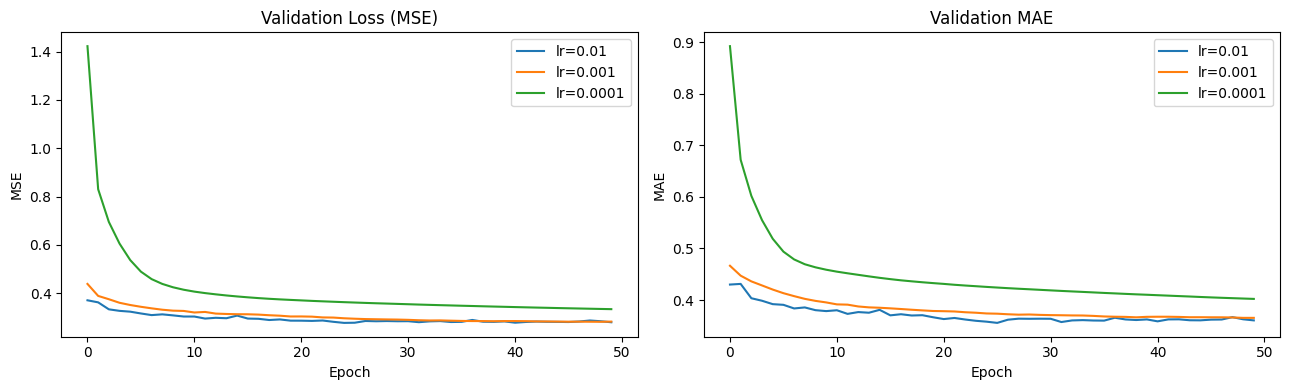

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for r in house_results:
    label = f"lr={r['learning_rate']}"
    axes[0].plot(r['history']['val_loss'], label=label)
    axes[1].plot(r['history']['val_mae'], label=label)

axes[0].set_title('Validation Loss (MSE)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE')
axes[0].legend()

axes[1].set_title('Validation MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()

plt.tight_layout()
plt.show()

### B.4 Contoh Prediksi

In [12]:
# Prediksi diambil dari model terakhir pada eksperimen
pred_akhir = model.predict(X_val_h, verbose=0).ravel()

contoh = pd.DataFrame({
    'Aktual': y_val_h[:10],
    'Prediksi': np.round(pred_akhir[:10], 4),
})

contoh['Selisih'] = np.round(contoh['Aktual'] - contoh['Prediksi'], 4)
contoh

,Aktual,Prediksi,Selisih
0,0.47700,0.5436,-0.0666
1,0.45800,1.5570,-1.0990
2,5.00001,4.1649,0.8351
3,2.18600,2.5939,-0.4079
4,2.78000,2.8675,-0.0875
5,1.58700,1.7180,-0.1310
6,1.98200,2.7063,-0.7243
7,1.57500,1.6000,-0.0250
8,3.40000,2.6425,0.7575
9,4.46600,4.4238,0.0422


## 9. Analisis Hasil

Seluruh angka pada bagian ini diambil dari output aktual notebook.

### Bagian A - Data Dummy

| Learning Rate | Final Train Loss | Test Loss | Prediksi Harga |
|---:|---:|---:|---:|
| 0.1 | 0.000006 | 0.009332 | 585.71 |
| 0.01 | 0.002722 | 0.011052 | 584.45 |
| 0.001 | 0.710428 | 0.741159 | 727.33 |

1. **Learning rate 0.1 paling cepat konvergen.** Final train loss mencapai 0.000006, jauh lebih kecil daripada 0.01 (0.002722) dan 0.001 (0.710428).
2. **Learning rate 0.001 belum konvergen dalam 100 epoch.** Loss masih 0.710428 dan prediksi harga 727.33, menyimpang jauh dari prediksi dua konfigurasi lain yang berada di sekitar 585.
3. **Learning rate 0.1 dan 0.01 memberi prediksi yang berdekatan.** Selisihnya hanya sekitar 1.26 satuan, sehingga keduanya sudah cukup baik untuk data dummy yang sederhana.
4. **Catatan.** Data uji hanya berisi 1 sampel, sehingga nilai test loss tidak cukup kuat untuk menyimpulkan performa generalisasi.

### Bagian B - California Housing

| Learning Rate | Val Loss (MSE) | Val MAE | RMSE | Waktu (s) |
|---:|---:|---:|---:|---:|
| 0.01 | 0.2793 | 0.3606 | 0.5285 | 76.22 |
| 0.001 | 0.2820 | 0.3655 | 0.5310 | 79.20 |
| 0.0001 | 0.3335 | 0.4022 | 0.5775 | 80.09 |

1. **Learning rate 0.01 memberikan hasil terbaik.** Val loss 0.2793, MAE 0.3606, dan RMSE 0.5285.
2. **Learning rate 0.001 sangat dekat dengan 0.01.** Selisih val loss hanya 0.0027 dan RMSE 0.0025, sehingga dalam 50 epoch keduanya menghasilkan performa yang hampir setara.
3. **Learning rate 0.0001 paling buruk.** Val loss naik menjadi 0.3335 dan RMSE 0.5775 karena konvergensi lebih lambat pada jumlah epoch yang sama.
4. **Waktu training hampir sama.** Rentangnya 76.22-80.09 detik untuk 50 epoch. Learning rate tidak mengubah biaya komputasi per epoch; perbedaan kecil berasal dari variasi eksekusi.
5. **Skala error.** Target California Housing dinyatakan dalam 100.000 USD. RMSE 0.5285 berarti sekitar 52.850 USD, sedangkan MAE 0.3606 berarti sekitar 36.060 USD.
6. **Contoh prediksi menunjukkan kesalahan pada nilai ekstrem.** Aktual 0.458 diprediksi 1.557 (selisih -1.099) dan aktual 5.00001 diprediksi 4.1649 (selisih 0.8351). Model cenderung mendekati nilai tengah: melebih-lebihkan harga rendah dan meremehkan harga tinggi. Contoh ini hanya 10 data, sehingga perlu dibaca sebagai ilustrasi, bukan kesimpulan umum.
7. **Catatan.** Target dibatasi pada nilai maksimum 5.00001 di dataset. Prediksi berada dalam skala target asli karena target tidak distandarisasi.